Only after we understand what our data contain, can we know how the data might be useful to us.

EDA - cleaning and reviewing data to derive insights such as descriptive statistics and correlations, and generate hypotheses for experiments.

eda results often informs the next step for the data set, like preparing the data for use in a ML model or even throughing the data out and gathering new data.

In [1]:
import kagglehub
import os
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("yasserh/titanic-dataset")

print("Path to dataset files:", path)

Path to dataset files: /home/jubel/.cache/kagglehub/datasets/yasserh/titanic-dataset/versions/1


In [2]:
csv_path = os.path.join(path, "Titanic-Dataset.csv")

df = pd.read_csv(csv_path)

## First look with .head()

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Gathering more .info()

Quick way to summerize the number of missing values in each column, data type of each column, and memory usage

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


### A closer look at categorical column

A common question about this is how many data points we have in each category. 

In [5]:
df['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [6]:
df['Pclass'].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

## .describe() numerical columns

In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Visualizing numerical data with histograms

Classic way of looking at the distribution of numerical data by splitting numerical data into discrete bins and visualizing the counts of values in each bin.

<Axes: xlabel='Age', ylabel='Count'>

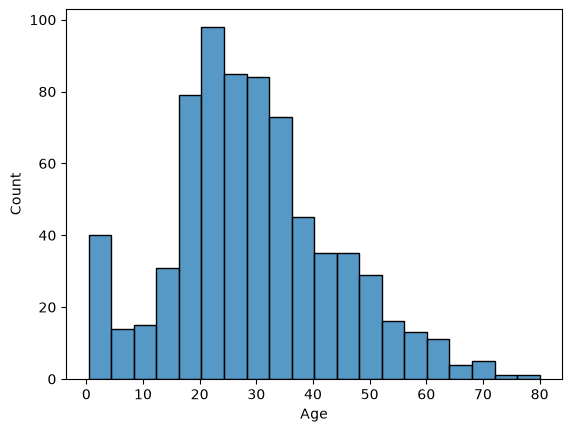

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x='Age')

### Data validation

We want to understand wether data types and ranges are as expected before we progress to far. 



In [9]:
df.dtypes # if we are only interested in data types

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

We might want to change the data type of a column.

We can do so with the .astype()

ex

books['year'] = books['year'].astype(int)

## Validating categorical data

We can compare values in a column by comparing them to a list of expected values using .isin()

In [10]:
df['Sex'].isin(['male', 'female'])

0      True
1      True
2      True
3      True
4      True
       ... 
886    True
887    True
888    True
889    True
890    True
Name: Sex, Length: 891, dtype: bool

In [11]:
no_gender=  ~df['Sex'].isin(['male', 'female']) # inverting

and then you can use this Series of Boolean values (a 'Boolean mask') to filter the dataframe

In [12]:
df[no_gender]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


## validating numerical data

Selecting only numerical


In [13]:
df.select_dtypes('number').head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
0,1,0,3,22.0,1,0,7.2500
1,2,1,1,38.0,1,0,71.2833
2,3,1,3,26.0,0,0,7.9250
3,4,1,1,35.0,1,0,53.1000
4,5,0,3,35.0,0,0,8.0500


In [14]:
df['Age'].min()

np.float64(0.42)

<Axes: xlabel='Age'>

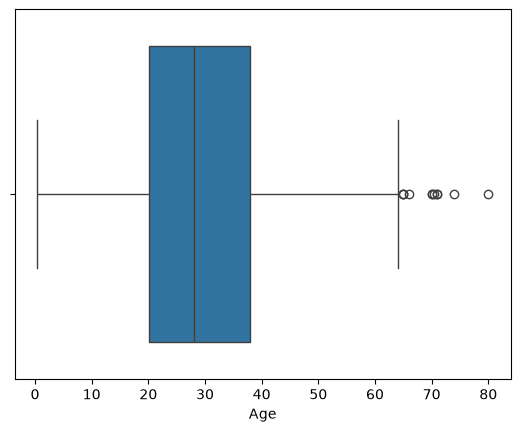

In [15]:
sns.boxplot(data=df, x='Age')

### We can also view the numerical data grouped by a categorical variable with y=

<Axes: xlabel='Age', ylabel='Sex'>

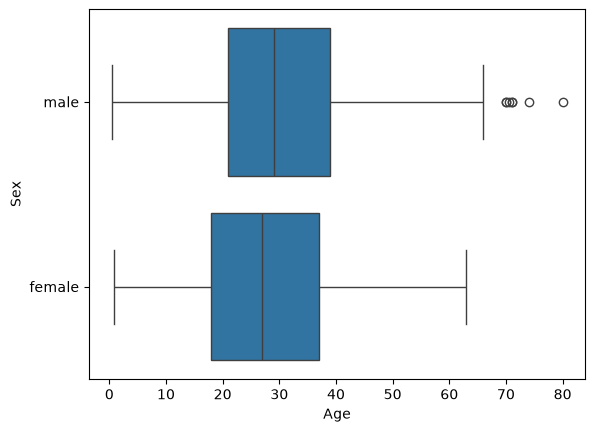

In [16]:
sns.boxplot(data=df, x='Age', y='Sex')

### Data summarization

Exploring characteristics of subsets of data further with the help of the .groupby() function

Aggregating function indicated how to summarize grouped data

In [17]:
df[['Sex', 'Age', 'Survived']].groupby('Sex').mean()

,Age,Survived
Sex,,
female,27.915709,0.742038
male,30.726645,0.188908


### Aggregating functions

.sum()
.count()
. min()
.max()
.var()
.std()

.agg() allows us to apply aggregating functions across a Dataframe, which is NOT grouped like in the previous example.


In [18]:
df[['Fare', 'Age']].agg(['mean', 'std'])

,Fare,Age
mean,32.204208,29.699118
std,49.693429,14.526497


You can even use a dictionary to specify wich aggregations to apply to which column

In [19]:
df.agg({"Age": ["mean", "max"], 'Fare':['median']})

,Age,Fare
mean,29.699118,NaN
max,80.000000,NaN
median,NaN,14.4542


### Named summary columns

In [20]:
df.groupby("Pclass").agg(
    mean_age=('Age', "mean"),
    mean_tariff=('Fare', 'mean')
)

,mean_age,mean_tariff
Pclass,,
1,38.233441,84.154687
2,29.877630,20.662183
3,25.140620,13.675550


### Visualizing categorical summaries

In Seaborn, bar plots will automatically calculate the mean of a quantitative variable like rating across grouped categorical data, such as the genre category 

In Seaborn, bar plots also show a 95% confidence interval for the mean as a vertical line on the top of each bar


<Axes: xlabel='Sex', ylabel='Survived'>

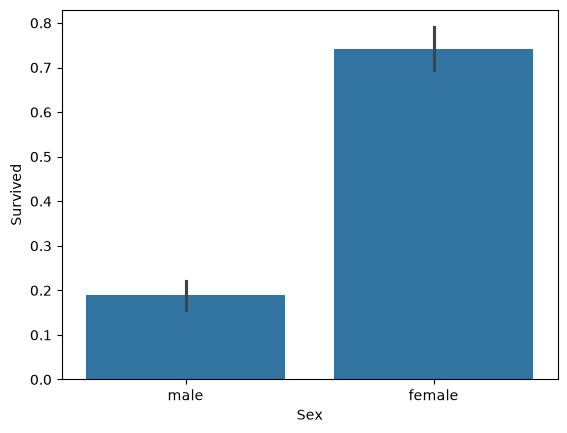

In [21]:
sns.barplot(data=df, x='Sex', y='Survived')

## Handling missing data

Why?

Missing data can affect the distribution. For the sample mean could for example be lower than the population mean. the data is then less representative of the population. Certain gorups disproportionately represented.

In [22]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## Strategies for addressing missing data

Drop missing values if they amount to five percent or less of all values

If more than 5% are missing, impute mean, median, mode depending on the context.

Or impute by supgroup.


In [23]:
threshold = len(df) * 0.05 # antalet rader som är 5 procent

We can use boolean indexing to filter for columns with missing values less than or equal to this threshold,

In [24]:
cols_to_drop_nans = df.columns[df.isna().sum() <= threshold]

cols_to_drop_nans

# These columns only have 5% or less missing values
# so we will remove the NaNs in these columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Embarked'],
      dtype='str')

In [25]:
df.dropna(subset=cols_to_drop_nans, inplace=True)

In [26]:
cols_with_missing_values = df.columns[df.isna().sum() > 0]
cols_with_missing_values

# so these two columns have MORE than 5 % missing values
# we will impute a summary statistics

Index(['Age', 'Cabin'], dtype='str')

In [27]:
for col in cols_with_missing_values[:-1]: 
    df[col] = df[col].fillna(df[col].mode()[0])

# filling with mode, except for the last column

Checking the remaining missing values

In [28]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [29]:
df['Cabin'].value_counts()
# numbers but the are really categories, 
# so it doesnt make any sense to fill 

Cabin
G6             4
C23 C25 C27    4
B96 B98        4
F33            3
E101           3
              ..
E17            1
A24            1
C50            1
B42            1
C148           1
Name: count, Length: 146, dtype: int64

Sometimes you might want to impute median by subpgroup

salaries_dict = salaries.groupby("Experience")["Salary_USD"].median().to_dict()

Here store the group data as a dictionary
And the impute by sub-group

salaries['Salary_USD'] = salaries['Salary_USD'].fillna(salaries['Experience'].map(salaries_dict))


.map() används för att ersätta varje värde i en Series med ett annat värde enligt en uppslagstabell (t.ex en dictionary)

## Converting and analyzing categorical data


In [30]:

df.select_dtypes('object').head()

# previewing all non-numeric data

/tmp/ipykernel_146320/616307181.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes('object').head()


,Name,Sex,Ticket,Cabin,Embarked
0,"Braund, Mr. Owen Harris",male,A/5 21171,NaN,S
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,PC 17599,C85,C
2,"Heikkinen, Miss. Laina",female,STON/O2. 3101282,NaN,S
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,113803,C123,S
4,"Allen, Mr. William Henry",male,373450,NaN,S


In [31]:
#examinin frequency in a specific column

df['Cabin'].value_counts()

Cabin
G6             4
C23 C25 C27    4
B96 B98        4
F33            3
E101           3
              ..
E17            1
A24            1
C50            1
B42            1
C148           1
Name: count, Length: 146, dtype: int64

In [32]:
# counting unique categories

df['Cabin'].nunique()

146

pd.Series.str.constrains() allows us to search a column for a specific string or multiple strings

In [33]:
df['Cabin'].str.contains('C|E')

0      False
1       True
2      False
3       True
4      False
       ...  
886    False
887    False
888    False
889     True
890    False
Name: Cabin, Length: 889, dtype: bool

In [34]:
# Any that STARTS with Andersson

anderssons = df['Name'].str.contains("^Andersson")
df[anderssons]



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
13,14,0,3,"Andersson, Mr. Anders Johan",male,39.0,1,5,347082,31.2750,NaN,S
68,69,1,3,"Andersson, Miss. Erna Alexandra",female,17.0,4,2,3101281,7.9250,NaN,S
119,120,0,3,"Andersson, Miss. Ellis Anna Maria",female,2.0,4,2,347082,31.2750,NaN,S
146,147,1,3,"Andersson, Mr. August Edvard (""Wennerstrom"")",male,27.0,0,0,350043,7.7958,NaN,S
541,542,0,3,"Andersson, Miss. Ingeborg Constanzia",female,9.0,4,2,347082,31.2750,NaN,S
542,543,0,3,"Andersson, Miss. Sigrid Elisabeth",female,11.0,4,2,347082,31.2750,NaN,S
610,611,0,3,"Andersson, Mrs. Anders Johan (Alfrida Konstant...",female,39.0,1,5,347082,31.2750,NaN,S
813,814,0,3,"Andersson, Miss. Ebba Iris Alfrida",female,6.0,4,2,347082,31.2750,NaN,S
850,851,0,3,"Andersson, Master. Sigvard Harald Elias",male,4.0,4,2,347082,31.2750,NaN,S


Creating a categorical column

salaries['Job_Category'] = np.select(conditions, job_categories, default='Other')

## Working with numeric data

Ta bort ,

df[kolumn] = df[kolumn].str.replace(",", "")

Ändra datatyp

.astype(float)

Skapa ny kolumn för annan valuta

salaries["Salaries_USD] = salaries["Salary_In_Rupees"] * 0.012



## Adding sumamry statistics into a DataFrame

Instead of making a summary table

ex

salaries["std_dev"] = salaries.groupby("Experience")["Salary_USD"].transform(lambda x: x.std())


ex adding a column for the median salary based on company size

salaries['median_by_comp_size'] = salaries.groupby("Company_Size") \
        ["Salary_USD"].transform(lambda x: x.median())
        

.transform() gives us the median for each row, not just each group

## How to handle outliers

Outliers are extreme values, may not accurately represent our data.

They can change the mean and standard deviation. 

Statistical tests and machine learning models need normally distributed data.

A starting point is with the .describe() method

IQR = 75th - 25th percentile

Upper Outliers > 75th percentile + (1.5 * IQR)
Lower Outliers < 25th percentile - (1.5 * IQR)

Questions to ask:

- Why do these outliers exist? 

- Is the data accurate? Could there have been an error in data collection? If so, remove them.



In [35]:
df['Fare'].describe()

count    889.000000
mean      32.096681
std       49.697504
min        0.000000
25%        7.895800
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

In [36]:
# finding the 75 th percentile

seventy_fifth = df['Fare'].quantile(0.75)
twenty_fifth = df['Fare'].quantile(0.25)

# Intecrquartile range
df_iqr = seventy_fifth - twenty_fifth

df_iqr
twenty_fifth


np.float64(7.8958)

Identifying outliers

In [37]:
# Upper threshold

upper = seventy_fifth + (1.5 * df_iqr)
lower = twenty_fifth - (1.5 * df_iqr)

print(upper, lower)

65.6563 -26.7605


<Axes: xlabel='Fare'>

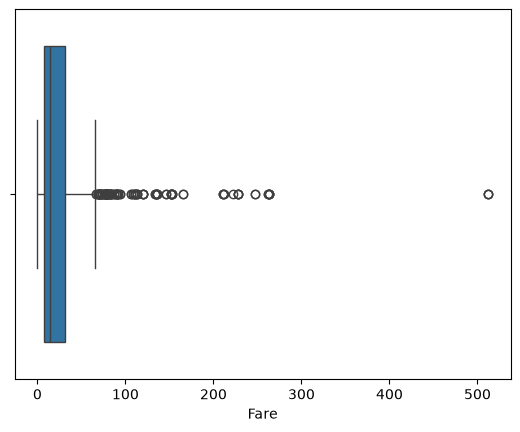

In [38]:
import seaborn as sns

sns.boxplot(data=df, x='Fare')

In [39]:
print(twenty_fifth)
print(seventy_fifth)
print(df_iqr)
print(lower)

7.8958
31.0
23.1042
-26.7605


In [40]:
outliers_price = df[(df['Fare'] < lower) | (df['Fare'] > upper)]
outliers_price

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,C23 C25 C27,S
31,32,1,1,"Spencer, Mrs. William Augustus (Marie Eugenie)",female,24.0,1,0,PC 17569,146.5208,B78,C
34,35,0,1,"Meyer, Mr. Edgar Joseph",male,28.0,1,0,PC 17604,82.1708,NaN,C
52,53,1,1,"Harper, Mrs. Henry Sleeper (Myna Haxtun)",female,49.0,1,0,PC 17572,76.7292,D33,C
...,...,...,...,...,...,...,...,...,...,...,...,...
846,847,0,3,"Sage, Mr. Douglas Bullen",male,24.0,8,2,CA. 2343,69.5500,NaN,S
849,850,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,24.0,1,0,17453,89.1042,C92,C
856,857,1,1,"Wick, Mrs. George Dennick (Mary Hitchcock)",female,45.0,1,1,36928,164.8667,NaN,S
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,24.0,8,2,CA. 2343,69.5500,NaN,S


<Axes: xlabel='Fare', ylabel='Count'>

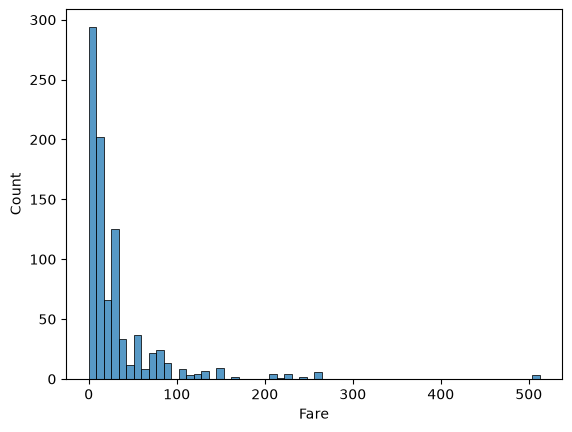

In [41]:
sns.histplot(data=df, x='Fare')

The Fare column is very right skewed, and the IQR -method is sensitive to that. That's why we got so many outliers.

## Dropping outliers

In [42]:
no_outliers = df[(df['Fare'] > lower) & (df['Fare'] < upper)]

no_outliers['Fare'].describe()

count    775.000000
mean      17.822091
std       13.578085
min        0.000000
25%        7.895800
50%       13.000000
75%       26.000000
max       65.000000
Name: Fare, dtype: float64

<Axes: xlabel='Fare', ylabel='Count'>

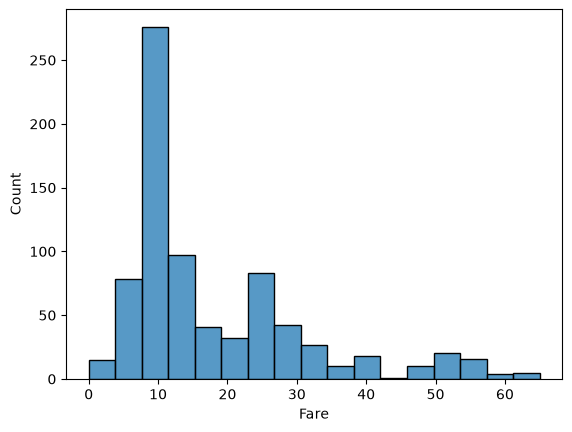

In [43]:
sns.histplot(data=no_outliers, x='Fare')

## Patterns over time

When data includes dates or time we want to examine if there are patterns over time. 

DateTime data needs to be explicitly declared to Pandas

In [44]:
df = pd.read_csv('data/divorces_2000-2015_translated.csv', parse_dates=['Divorce_date', 'DOB_partner_man', 'DOB_partner_woman', 'Date_of_marriage'])

/tmp/ipykernel_146320/1609713281.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv('data/divorces_2000-2015_translated.csv', parse_dates=['Divorce_date', 'DOB_partner_man', 'DOB_partner_woman', 'Date_of_marriage'])
/tmp/ipykernel_146320/1609713281.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv('data/divorces_2000-2015_translated.csv', parse_dates=['Divorce_date', 'DOB_partner_man', 'DOB_partner_woman', 'Date_of_marriage'])
/tmp/ipykernel_146320/1609713281.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv('data/divo

In [45]:
df.head()

,Divorce_date,Type_of_divorce,Nationality_partner_man,DOB_partner_man,Place_of_birth_partner_man,Birth_municipality_of_partner_man,Birth_federal_partner_man,Birth_country_partner_man,Age_partner_man,Residence_municipality_partner_man,...,Marriage_certificate_municipality,Marriage_certificate_federal,Level_of_education_partner_man,Employment_status_partner_man,Level_of_education_partner_woman,Employment_status_partner_woman,Marriage_duration,Marriage_duration_months,Num_Children,Custody
0,2006-09-06,Necesario,MEXICANA,2075-12-18,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,30.0,XALAPA,...,XALAPA,VERACRUZ,SECUNDARIA,OBRERO,SECUNDARIA,EMPLEADO,5.0,NaN,1.0,NaN
1,2000-01-02,Voluntario,MEXICANA,NaT,NaN,NaN,NaN,NaN,47.0,NaN,...,XALAPA,VERACRUZ,PREPARATORIA,ESTABLECIMIENTO,PREPARATORIA,EMPLEADO,NaN,NaN,NaN,NaN
2,2005-01-02,Necesario,MEXICANA,2055-02-22,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,49.0,NaN,...,XALAPA,VERACRUZ,PREPARATORIA,OBRERO,NaN,TRABAJADOR POR CUENTA PROPIA EN VIA PUBLICA,NaN,NaN,NaN,NaN
3,2006-01-02,Necesario,MEXICANA,2064-01-20,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,42.0,XALAPA,...,XALAPA,VERACRUZ,PROFESIONAL,EMPLEADO,PREPARATORIA,EMPLEADO,18.0,NaN,2.0,MADRE
4,2006-01-02,Necesario,MEXICANA,2075-10-30,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,30.0,COATEPEC,...,XALAPA,VERACRUZ,PROFESIONAL,EMPLEADO,PREPARATORIA,NO TRABAJA,7.0,NaN,2.0,MADRE


In [46]:
divorce = df
divorce

,Divorce_date,Type_of_divorce,Nationality_partner_man,DOB_partner_man,Place_of_birth_partner_man,Birth_municipality_of_partner_man,Birth_federal_partner_man,Birth_country_partner_man,Age_partner_man,Residence_municipality_partner_man,...,Marriage_certificate_municipality,Marriage_certificate_federal,Level_of_education_partner_man,Employment_status_partner_man,Level_of_education_partner_woman,Employment_status_partner_woman,Marriage_duration,Marriage_duration_months,Num_Children,Custody
0,2006-09-06,Necesario,MEXICANA,2075-12-18,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,30.0,XALAPA,...,XALAPA,VERACRUZ,SECUNDARIA,OBRERO,SECUNDARIA,EMPLEADO,5.0,NaN,1.0,NaN
1,2000-01-02,Voluntario,MEXICANA,NaT,NaN,NaN,NaN,NaN,47.0,NaN,...,XALAPA,VERACRUZ,PREPARATORIA,ESTABLECIMIENTO,PREPARATORIA,EMPLEADO,NaN,NaN,NaN,NaN
2,2005-01-02,Necesario,MEXICANA,2055-02-22,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,49.0,NaN,...,XALAPA,VERACRUZ,PREPARATORIA,OBRERO,NaN,TRABAJADOR POR CUENTA PROPIA EN VIA PUBLICA,NaN,NaN,NaN,NaN
3,2006-01-02,Necesario,MEXICANA,2064-01-20,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,42.0,XALAPA,...,XALAPA,VERACRUZ,PROFESIONAL,EMPLEADO,PREPARATORIA,EMPLEADO,18.0,NaN,2.0,MADRE
4,2006-01-02,Necesario,MEXICANA,2075-10-30,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,30.0,COATEPEC,...,XALAPA,VERACRUZ,PROFESIONAL,EMPLEADO,PREPARATORIA,NO TRABAJA,7.0,NaN,2.0,MADRE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4918,2012-10-31,Voluntario,MEXICANA,1977-10-29,MORELIA,MORELIA,MICHOACAN,MEXICO,35.0,MORELIA,...,XALAPA,VERACRUZ,PROFESIONAL,EMPLEADO,PROFESIONAL,EMPLEADO,3.0,11.0,NaN,NaN
4919,2013-10-31,Voluntario,MEXICANA,1982-10-11,VERACRUZ,VERACRUZ,VERACRUZ,MEXICO,30.0,XALAPA,...,XALAPA,VERACRUZ,PROFESIONAL,EMPLEADO,PROFESIONAL,EMPLEADO,1.0,NaN,NaN,NaN
4920,2013-10-31,Voluntario,MEXICANA,2054-10-28,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,59.0,EMILIANO ZAPATA,...,XALAPA,VERACRUZ,PROFESIONAL,EMPLEADO,PROFESIONAL,EMPLEADO,35.0,NaN,2.0,NaN
4921,2012-12-31,Voluntario,MEXICANA,2058-07-02,TLAPACOYAN,TLAPACOYAN,VERACRUZ,MEXICO,54.0,XALAPA,...,TLAPACOYAN,VERACRUZ,PREPARATORIA,NaN,PRIMARIA,NO TRABAJA,33.0,NaN,2.0,NaN


In [47]:
divorce.dtypes

Divorce_date                            datetime64[us]
Type_of_divorce                                    str
Nationality_partner_man                            str
DOB_partner_man                         datetime64[us]
Place_of_birth_partner_man                         str
Birth_municipality_of_partner_man                  str
Birth_federal_partner_man                          str
Birth_country_partner_man                          str
Age_partner_man                                float64
Residence_municipality_partner_man                 str
Residence_federal_partner_man                      str
Residence_country_partner_man                      str
Monthly_income_partner_man_peso                float64
Occupation_partner_man                             str
Place_of_residence_partner_man                     str
Nationality_partner_woman                          str
DOB_partner_woman                       datetime64[us]
DOB_registration_date_partner_woman                str
Place_of_b

pd.to_datetime() finns också om man vill ändra efter

This is great if a data frame has seperate columns for month, day, year. Then we combine it into a sinlge DateTime value by passing them to pd.to_datetime

We might want to extrancts parts of a full date using dt.month, dt.day and dt.year attributes

In [48]:
divorce['Divorce_month'] = divorce['Divorce_date'].dt.month 
divorce.head()

,Divorce_date,Type_of_divorce,Nationality_partner_man,DOB_partner_man,Place_of_birth_partner_man,Birth_municipality_of_partner_man,Birth_federal_partner_man,Birth_country_partner_man,Age_partner_man,Residence_municipality_partner_man,...,Marriage_certificate_federal,Level_of_education_partner_man,Employment_status_partner_man,Level_of_education_partner_woman,Employment_status_partner_woman,Marriage_duration,Marriage_duration_months,Num_Children,Custody,Divorce_month
0,2006-09-06,Necesario,MEXICANA,2075-12-18,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,30.0,XALAPA,...,VERACRUZ,SECUNDARIA,OBRERO,SECUNDARIA,EMPLEADO,5.0,NaN,1.0,NaN,9
1,2000-01-02,Voluntario,MEXICANA,NaT,NaN,NaN,NaN,NaN,47.0,NaN,...,VERACRUZ,PREPARATORIA,ESTABLECIMIENTO,PREPARATORIA,EMPLEADO,NaN,NaN,NaN,NaN,1
2,2005-01-02,Necesario,MEXICANA,2055-02-22,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,49.0,NaN,...,VERACRUZ,PREPARATORIA,OBRERO,NaN,TRABAJADOR POR CUENTA PROPIA EN VIA PUBLICA,NaN,NaN,NaN,NaN,1
3,2006-01-02,Necesario,MEXICANA,2064-01-20,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,42.0,XALAPA,...,VERACRUZ,PROFESIONAL,EMPLEADO,PREPARATORIA,EMPLEADO,18.0,NaN,2.0,MADRE,1
4,2006-01-02,Necesario,MEXICANA,2075-10-30,XALAPA - ENRIQUEZ,XALAPA,VERACRUZ,MEXICO,30.0,COATEPEC,...,VERACRUZ,PROFESIONAL,EMPLEADO,PREPARATORIA,NO TRABAJA,7.0,NaN,2.0,MADRE,1


In [49]:
divorce.info()

<class 'pandas.DataFrame'>
RangeIndex: 4923 entries, 0 to 4922
Data columns (total 42 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   Divorce_date                          4923 non-null   datetime64[us]
 1   Type_of_divorce                       4923 non-null   str           
 2   Nationality_partner_man               4922 non-null   str           
 3   DOB_partner_man                       4542 non-null   datetime64[us]
 4   Place_of_birth_partner_man            4797 non-null   str           
 5   Birth_municipality_of_partner_man     4794 non-null   str           
 6   Birth_federal_partner_man             4795 non-null   str           
 7   Birth_country_partner_man             4796 non-null   str           
 8   Age_partner_man                       4816 non-null   float64       
 9   Residence_municipality_partner_man    4599 non-null   str           
 10  Residence_f

In [50]:
divorce.isna().sum()

Divorce_date                               0
Type_of_divorce                            0
Nationality_partner_man                    1
DOB_partner_man                          381
Place_of_birth_partner_man               126
Birth_municipality_of_partner_man        129
Birth_federal_partner_man                128
Birth_country_partner_man                127
Age_partner_man                          107
Residence_municipality_partner_man       324
Residence_federal_partner_man            323
Residence_country_partner_man            324
Monthly_income_partner_man_peso         1419
Occupation_partner_man                   529
Place_of_residence_partner_man           321
Nationality_partner_woman                  3
DOB_partner_woman                        452
DOB_registration_date_partner_woman     2679
Place_of_birth_partner_woman             140
Birth_municipality_of_partner_woman      139
Birth_federal_partner_woman              140
Birth_country_partner_woman              139
Age_partne

## Visusalizing patterns over time

Line plots are a great way to examine relationships between variables.

<Axes: xlabel='Divorce_month', ylabel='Marriage_duration'>

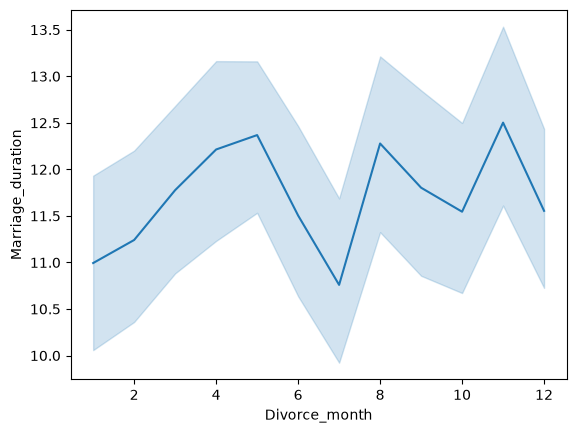

In [51]:
sns.lineplot(data=divorce, x= "Divorce_month", y='Marriage_duration')

A wide confidence interval suggests that further analyses is needed.

In [52]:
divorce['Divorce_month'] = divorce['Divorce_date'].dt.month

<Axes: xlabel='Divorce_month', ylabel='Num_Children'>

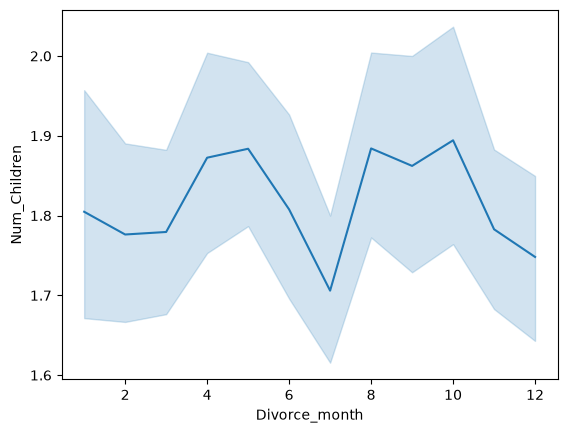

In [53]:
sns.lineplot(data=divorce, x='Divorce_month', y='Num_Children')

Seaborn automatically averages the number value on the y-axis! Here it becomes the averages number of children.

## Correlation

Getting a sense of relationships between variabels is important for evaluating how data should be used

Describes direction and strength of relationship between two variables

divorce.corr(numeric_only=True)

In [54]:
divorce.corr(numeric_only=True)

,Age_partner_man,Monthly_income_partner_man_peso,Age_partner_woman,Monthly_income_partner_woman_peso,Marriage_duration,Marriage_duration_months,Num_Children,Divorce_month
Age_partner_man,1.000000,0.033578,0.861511,0.091953,0.718444,0.013064,0.419191,0.004618
Monthly_income_partner_man_peso,0.033578,1.000000,0.021836,0.201451,0.029531,-0.007417,-0.009039,-0.027466
Age_partner_woman,0.861511,0.021836,1.000000,0.108949,0.752404,-0.011300,0.427406,0.006305
Monthly_income_partner_woman_peso,0.091953,0.201451,0.108949,1.000000,0.079284,-0.001558,-0.003630,-0.005010
Marriage_duration,0.718444,0.029531,0.752404,0.079284,1.000000,-0.010753,0.480123,0.014958
Marriage_duration_months,0.013064,-0.007417,-0.011300,-0.001558,-0.010753,1.000000,0.044861,0.050131
Num_Children,0.419191,-0.009039,0.427406,-0.003630,0.480123,0.044861,1.000000,-0.001328
Divorce_month,0.004618,-0.027466,0.006305,-0.005010,0.014958,0.050131,-0.001328,1.000000


### Let's wrap out divorce.corr() results in a Seaborn heatmap for a quick visual 

A heatmap has the befit of color coding so that strong positive and negative correlations are easier to spot.

<Axes: >

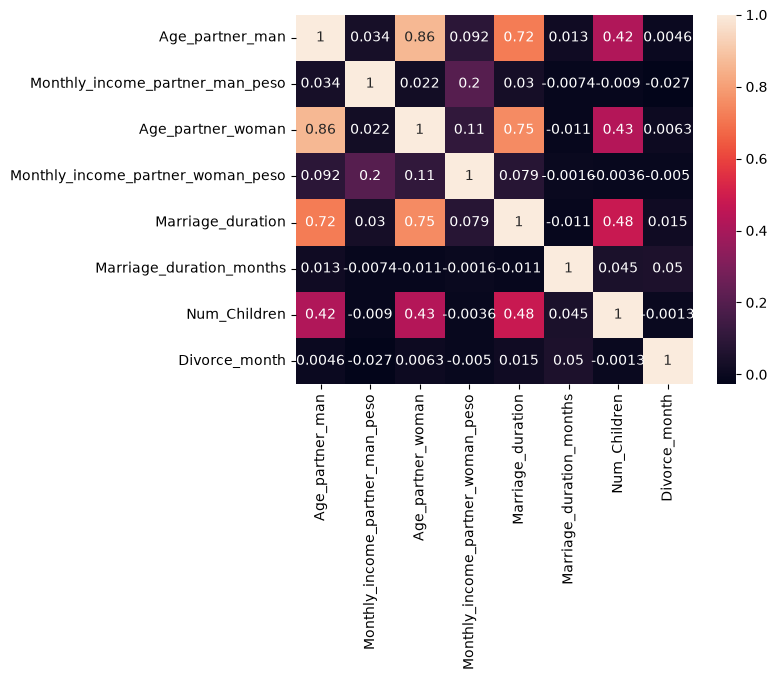

In [55]:
sns.heatmap(divorce.corr(numeric_only=True), annot=True)

We must always interpret correlations within the context of our data!

We must also remember that the Pearson coefficient only describes the linear correlation between vairables.


Another relationship, such as quadratic, could be a better fit for the data. 

This is why it's important to complement our correlation calculations with scatter plots!



In [56]:
divorce.rename(columns={'Monthly_income_partner_man_peso': 'man_income'}, inplace=True) 
divorce.rename(columns={'Monthly_income_partner_woman_peso': 'woman_income'}, inplace=True) 

<Axes: xlabel='man_income', ylabel='woman_income'>

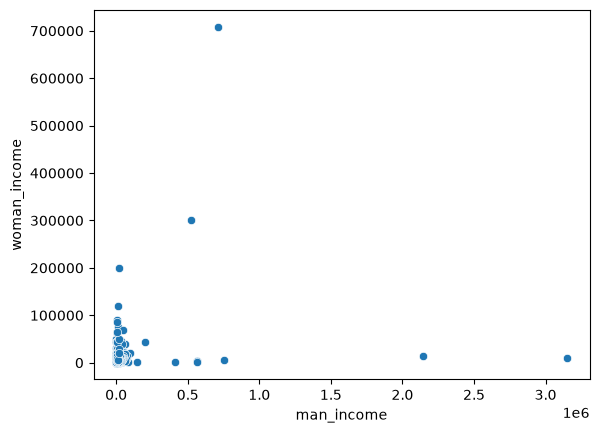

In [57]:
sns.scatterplot(data=divorce, x='man_income', y='woman_income' )

#### We can take our scatterplots to the next level with Seaborn's pairplot

When passed a DataFrame, pairplot plots all pairwise relationships between numerical variables in one visualization. On the diagonal form upperleft, we see the distribution of each variable's observations.

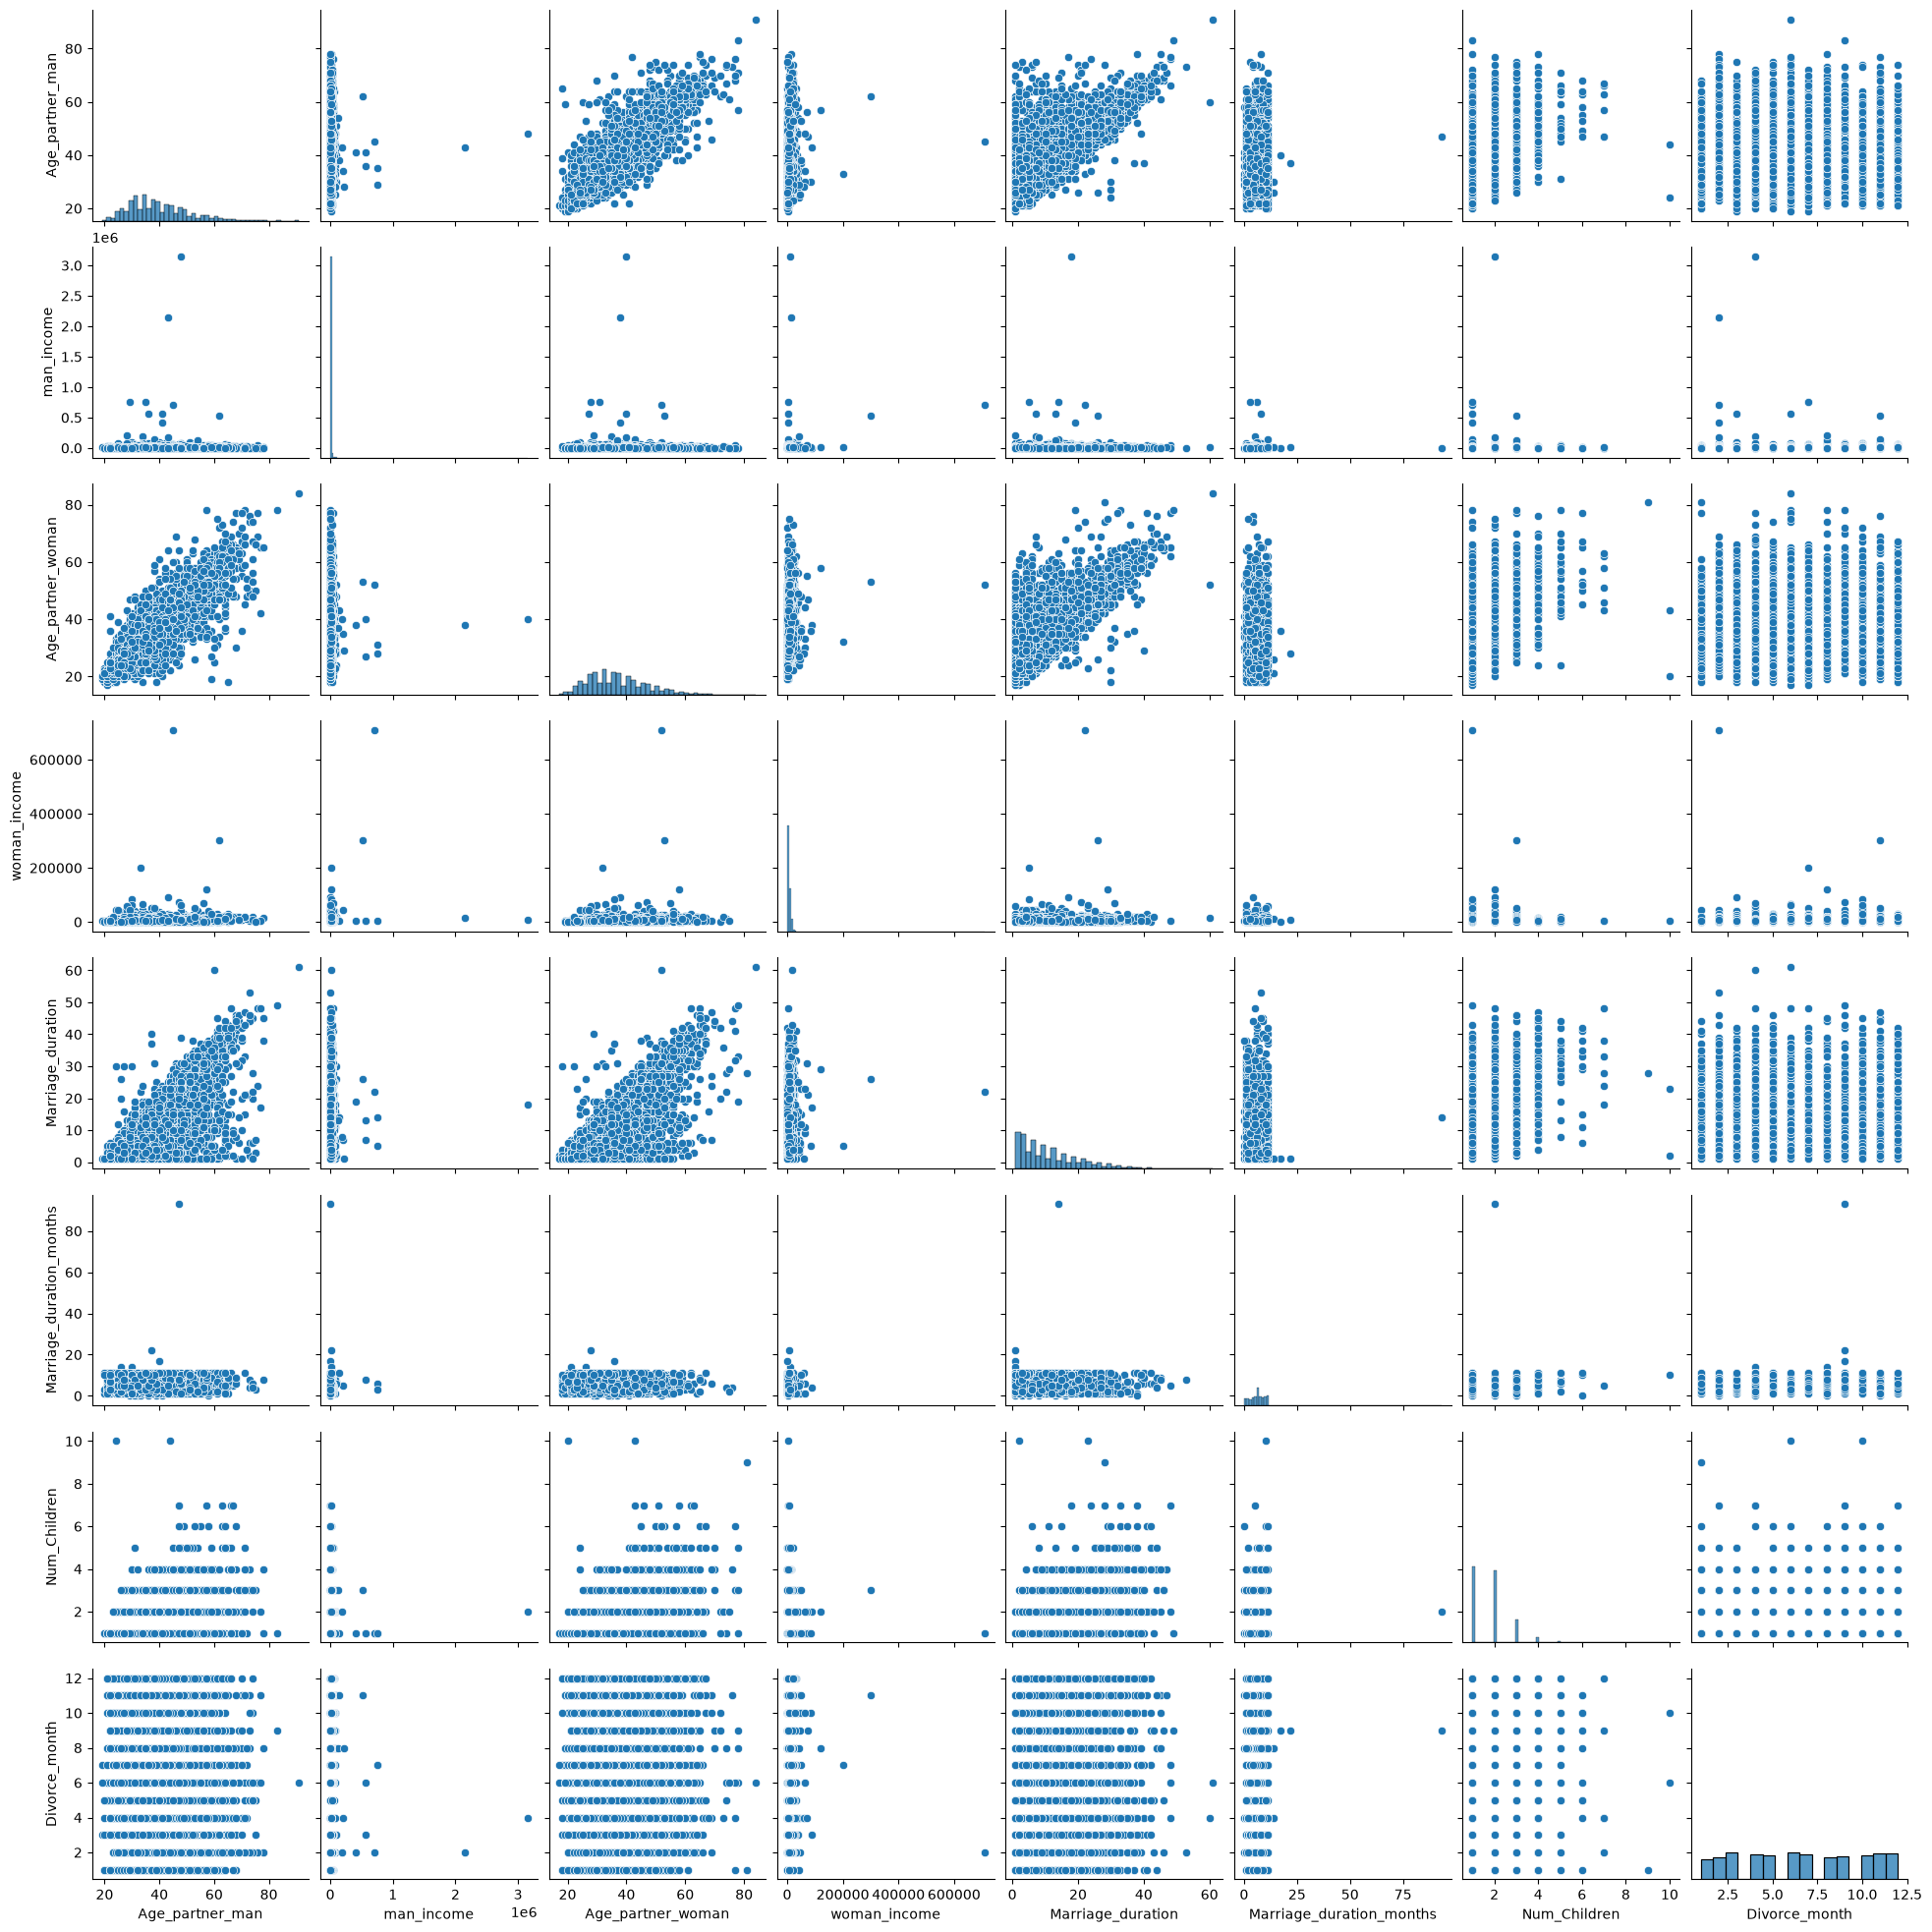

In [58]:
sns.pairplot(data=divorce)

#### We can limit the number of plotted relationships by setting the vars argument equalt to the variables of interest

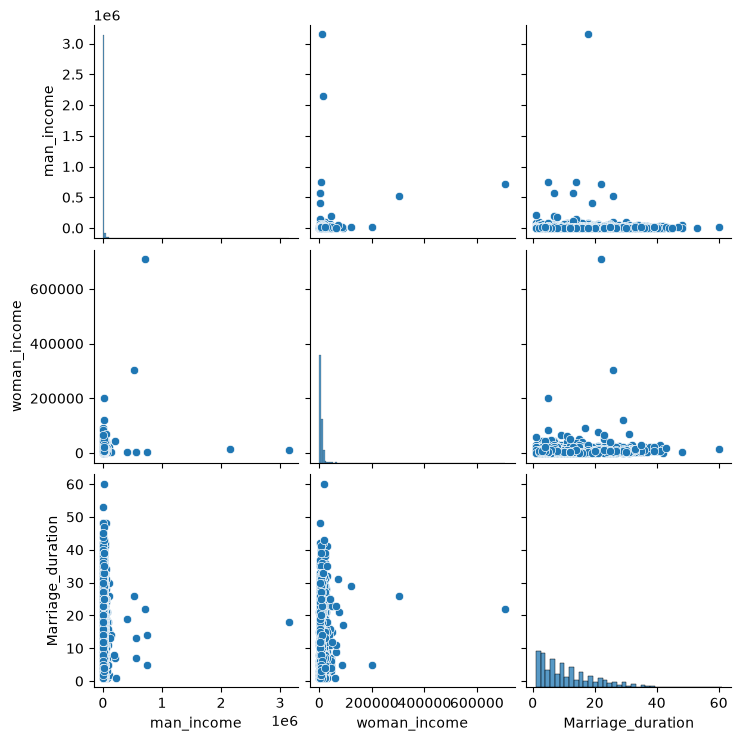

In [59]:
sns.pairplot(data=divorce, vars=["man_income", "woman_income", "Marriage_duration"])

the income of each partner and the marriage duration variable all have fairly weak relationship with each other

We also notice in the bottom right plot that the distribution of marriage duration includes many shorter marriages and fewer longer marriages.

## Factor relationships and distributions

Categorical variables, or factors, also have relationships

In [60]:
divorce["Level_of_education_partner_man"].value_counts()

Level_of_education_partner_man
PROFESIONAL        2536
PREPARATORIA       1010
SECUNDARIA          692
PRIMARIA            342
SIN ESCOLARIDAD      25
OTRO                 14
Name: count, dtype: int64

Categorical variables are harder to summarize numerically, so we often rely on visualizations to explore their relationships. 



<Axes: xlabel='Marriage_duration', ylabel='Count'>

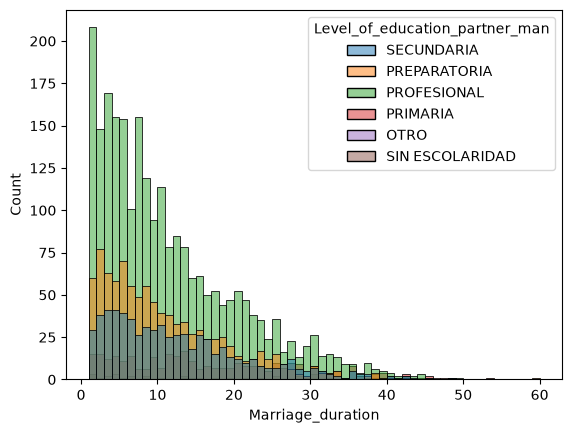

In [61]:
sns.histplot(data=divorce, x='Marriage_duration', hue="Level_of_education_partner_man", binwidth=1)

The resulting histogram, with the factor set as hue, reinforces what we saw in value counts: we have a lot of information on males woth professional-level education. However, because education levels are stacked on top of eachother, the relationship duration and male educationlevel isn't super clear.

Seaborn's Kernel Density Estimate or KDE plots addeess this issue

<Axes: xlabel='Marriage_duration', ylabel='Density'>

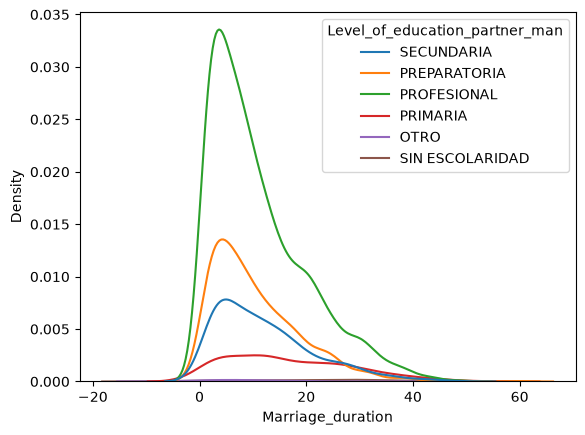

In [62]:
sns.kdeplot(data=divorce, x='Marriage_duration', hue='Level_of_education_partner_man')

Similar to histograms, KDEs allow us to visualize distributions. KDEs are considered more interpretable, though, especially when  multiple distributions are shows as they are here.

Notice that the location of the peak marriage duration for each level of the male partner's education is more identifiable in this KDE's plot than it was in the histogram.

However, due to the smoothing algorithm used in KDE plots, the curve can include values that don't make sense, so it's important to set good smoothing parametres. 

ex we want to fix less than 0 duration of marriage with cut=0

<Axes: xlabel='Marriage_duration', ylabel='Density'>

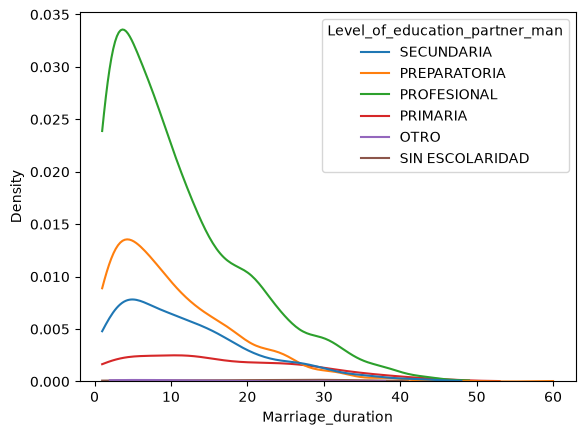

In [63]:
sns.kdeplot(data=divorce, x='Marriage_duration', hue='Level_of_education_partner_man', cut=0)

If we're interested in the cumulative distribution function, we can set the cumulative keyword argument to True

<Axes: xlabel='Marriage_duration', ylabel='Density'>

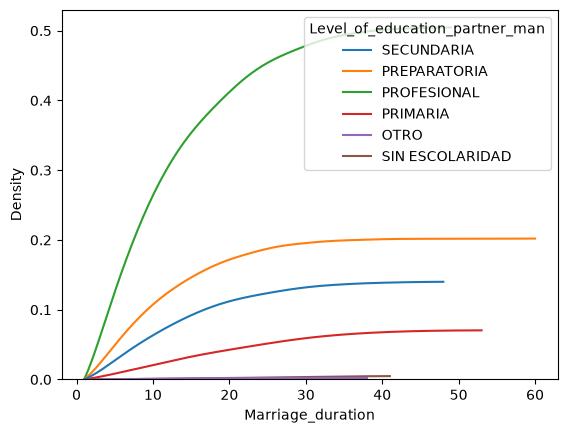

In [64]:
import scipy

sns.kdeplot(data=divorce, x='Marriage_duration', hue='Level_of_education_partner_man', cut=0, cumulative=True)

This graph describes the probability that marriage duration is less than or equal to the value on the x-axis for each level of male partner education

In [65]:
divorce.columns

Index(['Divorce_date', 'Type_of_divorce', 'Nationality_partner_man',
       'DOB_partner_man', 'Place_of_birth_partner_man',
       'Birth_municipality_of_partner_man', 'Birth_federal_partner_man',
       'Birth_country_partner_man', 'Age_partner_man',
       'Residence_municipality_partner_man', 'Residence_federal_partner_man',
       'Residence_country_partner_man', 'man_income', 'Occupation_partner_man',
       'Place_of_residence_partner_man', 'Nationality_partner_woman',
       'DOB_partner_woman', 'DOB_registration_date_partner_woman',
       'Place_of_birth_partner_woman', 'Birth_municipality_of_partner_woman',
       'Birth_federal_partner_woman', 'Birth_country_partner_woman',
       'Age_partner_woman', 'Place_of_residence_partner_woman',
       'Residence_municipality_partner_woman',
       'Residence_federal_partner_woman', 'Residence_country_partner_woman',
       'Occupation_partner_woman', 'woman_income', 'Date_of_marriage',
       'Marriage_certificate_place', 'Marriage

In [66]:
divorce['Date_of_marriage']

0      2000-06-26
1      1977-02-17
2      2075-12-18
3      1987-03-12
4      1998-11-14
          ...    
4918   2008-10-25
4919   2012-05-26
4920   1978-02-06
4921   1979-05-11
4922   2009-08-22
Name: Date_of_marriage, Length: 4923, dtype: datetime64[us]

In [67]:
divorce['DOB_partner_man']

0      2075-12-18
1             NaT
2      2055-02-22
3      2064-01-20
4      2075-10-30
          ...    
4918   1977-10-29
4919   1982-10-11
4920   2054-10-28
4921   2058-07-02
4922   2060-06-22
Name: DOB_partner_man, Length: 4923, dtype: datetime64[us]

#### Is there a relationship between age at marriage and education level?


In [68]:
divorce['man_age_marriage'] = divorce['Date_of_marriage'] - divorce['DOB_partner_man']
divorce['woman_age_marriage'] = divorce['Date_of_marriage'] - divorce['DOB_partner_woman']

this didn't really work out. Data camp did year of marriage minus year of birth for each person, but some more work would be needed here on the values 

Anyway the point is to do a scatterplot to see relationship between woman_age_marriage and man_age_marriage, and set hue to education_man

One requirement out data must satisfy regardless of our plans after eda - it must be representative of the population we wish to study.

With categorical data - one of the most important considerations is about the representation of classes, which another term for labels. 

Tex - om vi vill undersöka en populations åsikter om äktenskap. Om vi vet deras äktenskapsstatus, och bara några få ÄR gifta - är detta stickprovet representativt? Det blir class imbalance när en klass i en kategorisk kolumn är absolut vanligast. Tex de flesta är skildai vårt stickprov. Detta kan göra resultatet biased. Särskilt om denna klassen inte är vanligare i populationen.

In [70]:
# class frequency with .value_counts()

# relative class frequenct

divorce['Type_of_divorce'].value_counts(normalize=True)

# this returns relative frequencies for each class
# We can think about whether the classes are representative

Type_of_divorce
Necesario     0.513508
Voluntario    0.486492
Name: proportion, dtype: float64

## Cross-tabulation

Another method for looking at class frequency is cross-tabulation, which enables us to examine the frequency of combinations of classes.

In [71]:
pd.crosstab(divorce['Employment_status_partner_man'], divorce['Employment_status_partner_woman'])

Employment_status_partner_woman,EMPLEADO,ESTABLECIMIENTO,JORNALERO O PEON,MIEMBRO DE COOPERATIVA,NO TRABAJA,OBRERO,PATRON O EMPRESARIO,TRABAJA EN SU VIVIENDA,TRABAJADOR NO REMUNERADO,TRABAJADOR POR CUENTA PROPIA EN VIA PUBLICA
Employment_status_partner_man,,,,,,,,,,
EMPLEADO,2776,64,0,0,782,1,23,15,25,12
ESTABLECIMIENTO,90,46,0,1,45,0,3,1,5,2
JORNALERO O PEON,7,0,0,0,25,0,0,0,3,1
MIEMBRO DE COOPERATIVA,2,0,0,1,0,0,0,0,0,0
NO TRABAJA,80,0,0,0,96,0,1,2,8,2
OBRERO,19,1,1,0,13,3,1,1,2,1
PATRON O EMPRESARIO,58,3,0,0,22,0,23,3,3,0
TRABAJA EN SU VIVIENDA,11,2,0,0,4,0,0,0,0,0
TRABAJADOR NO REMUNERADO,5,0,0,0,2,0,0,0,2,0


The values will be the count of combined observations

You can also add aggregated values in pd.crosstab() with values=planes['Price], aggfunc='median'

If you also add expected values, you can see if some values are not representitive of the population.

### Generating new features

Sometimes the format of our data can limit our ability to detect relationships or inhibit the potential performance of ML-models.

Checking the datatypes, you might spot a feature that SHOULD be numeric, and if you change it will be included in a heatmap, and you'll be able to spot more relationships potentially.

Ex feature 'Total_Stops' have the classes 1 stop, non-stop, 2/3/4 stop as value-names. non-stop should be changed to 0 and you need to remove the string 'stop' before converting the datatype to int.

str.replace(" stops", "")

str.replace("non-stop", "0")

### Extracting month and weekday

creating a new column with dt.weekday for example

or hour of departure and arrival for flights and check correlation with prices

### Creating categories

We can group numeric data and label them as classes

for example with quartiles:

twenty_fifth = planes['Price'].quantile(0.25)
median = planes['Price'].median()

labels = ['Economy', 'Premium Economy', 'Business Class', 'First Class']

bins = [0, twenty_fifth, median, seventy_fifth, maximum]

planes('Price_Category') = pd.cut(planes['Price'], labels=labels, bins=bins)

Then make countplot, with the hue as Price_Category

## Generating hypothesis

## Spurious correlation

After heat map, then doing a scatterplot, with duration, price and total stops as hue...

We might think that Total_Stops is correlated with Price, but doing the scatter plot we see that, in fact its just duration that is correlated and total stops mostly maps to duration ranges.

### When performing EDA we must ask - how do we know what we are observing is true?

- would data from a different time give the sam results?

- detecting relationships, differences and patterns: 
    - we must use a bransch of statistics called Hypothesis Testing.

- Hypothesis testing requires, prior to data collection: 
    - generating a hypthesis or question
    - a decision on what statistical test to use, in order to reasonably conclude whether the hypothesis was true or false.

### Data snooping

Let's imagine we work for an agency regulating airlines, so we have our planes data available as part of our day-to-day work without any specific question in mind. 

We might be thinking, well, we have all this data, so why not just come up with questions and run some tests now?

But we didnt collect the data with the aim of answering these questions. We've already looked at the data extensivly and generated new features, so we might be bias and generate hypotheses that we are confident xist to prove ourselves right!
We could also be tempted to run lots of tests, since we have lots of data. 

The acts of excessive exploratory analysis, the generation of multiple hypotheses, and the execution of multiple statistical tests are collectively known as data snooping, or p-hacking. Chances are, if we look at enough data and run enough tests, we will find a significant result. 

### Generating hypothesis

So how do we generate hypothesis? We perform some EDA. We might have a hunch about something, we can plot the data and see if it seems to be the case.

From there we need to design our experiment. This involves many steps, such as:

- choosing a sample
- calculating how many data points we need
- deciding what statistical test to run

These steps are outside the steps of this tutorial, but at least now we have a sense of the advantages, limitations, and overall remit (ansvarsområde) of exploratory data analysis in a data science workflow. 

CHATGPT:

EDA is for discovering patterns and generating hypotheses.  Observations in eda is factual for the data you have. The problemis when you try to generalize or explain the patterns. You might find relationships that happend by chance. "EDA generates hypotheses; it doesn't confirm them"

When EDA has given you a hypothesis, you can test it. If causal claims matter, you can run an experiment or use causal inference methods. 

about data snooping: if you use the same dataset to explore until you find and interesting pattern, and then test that exact pattern on the same data, the statistical significance can be misleading because the hypothesis was influeced by the data itself.

The key is not to mistake an exploratory finding for a confirmed or causal result.